In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("puneet6060/intel-image-classification")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Path to dataset files: /kaggle/input/intel-image-classification


In [2]:
import tensorflow as tf
from tensorflow.keras import models,layers
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix,classification_report
from sklearn.model_selection import train_test_split
import os

In [3]:
os.listdir(path)

['seg_train', 'seg_pred', 'seg_test']

In [4]:
train_path = os.path.join(path, "seg_train", "seg_train")
test_path = os.path.join(path, "seg_test", "seg_test")

In [5]:
print("Training path:",train_path)
print("Test path-",test_path)

Training path: /kaggle/input/intel-image-classification/seg_train/seg_train
Test path- /kaggle/input/intel-image-classification/seg_test/seg_test


In [6]:
print("Training classes:")
print(os.listdir(train_path))
print("\nTest classes:")
print(os.listdir(test_path))

Training classes:
['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']

Test classes:
['mountain', 'street', 'buildings', 'sea', 'forest', 'glacier']


NUMBER OF CLASSES

In [7]:
class_num=len(os.listdir(train_path))
print("Number of classes:-",class_num)

Number of classes:- 6


In [8]:
for class_name in os.listdir(train_path):
    class_path = os.path.join(train_path, class_name)

    if os.path.isdir(class_path):
        print(f"{class_name}: {len(os.listdir(class_path))} images")

mountain: 2512 images
street: 2382 images
buildings: 2191 images
sea: 2274 images
forest: 2271 images
glacier: 2404 images


buildings (150, 150) RGB
forest (150, 150) RGB
glacier (150, 150) RGB
mountain (150, 150) RGB
sea (150, 150) RGB
street (150, 150) RGB


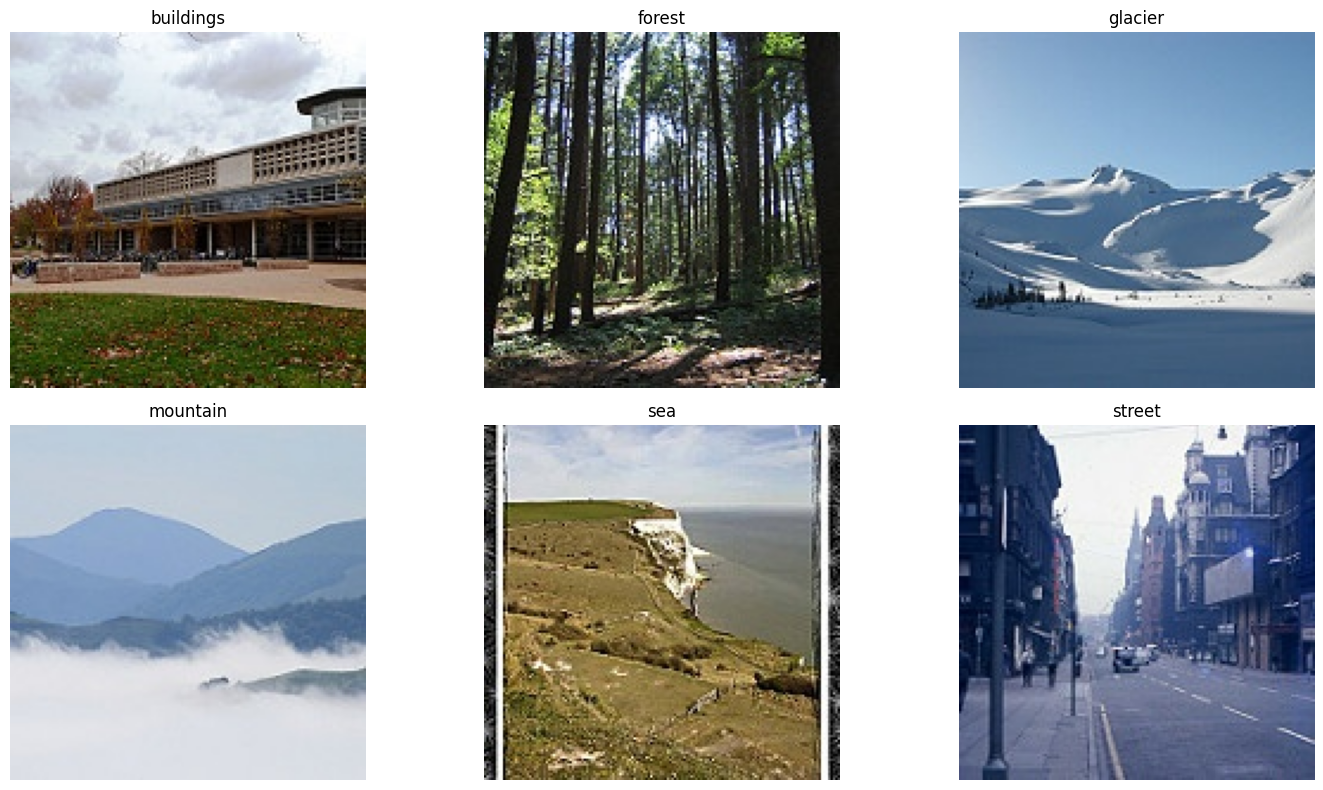

In [9]:
from PIL import Image
classes = sorted(os.listdir(train_path))

plt.figure(figsize=(15, 8))

for i,class_name in enumerate(classes):
    class_path = os.path.join(train_path, class_name)
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path)
    print(class_name, image.size,image.mode)
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
image_size=150
batch_size=32
channels=3
epochs=50

NORMALIZING PIXEL VALUES

In [11]:
normalization_layer = tf.keras.layers.Rescaling(1/255)

In [12]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(image_size,image_size),
    batch_size=batch_size,
    validation_split=0.20,
    subset="training",
    seed=42,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(image_size,image_size),
    batch_size=batch_size,
    validation_split=0.20,
    subset="validation",
    seed=42,
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(image_size,image_size),
    batch_size=batch_size,
    shuffle=False
)
print("Classes:", train_ds.class_names)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [13]:
class_names=train_ds.class_names
class_names

['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

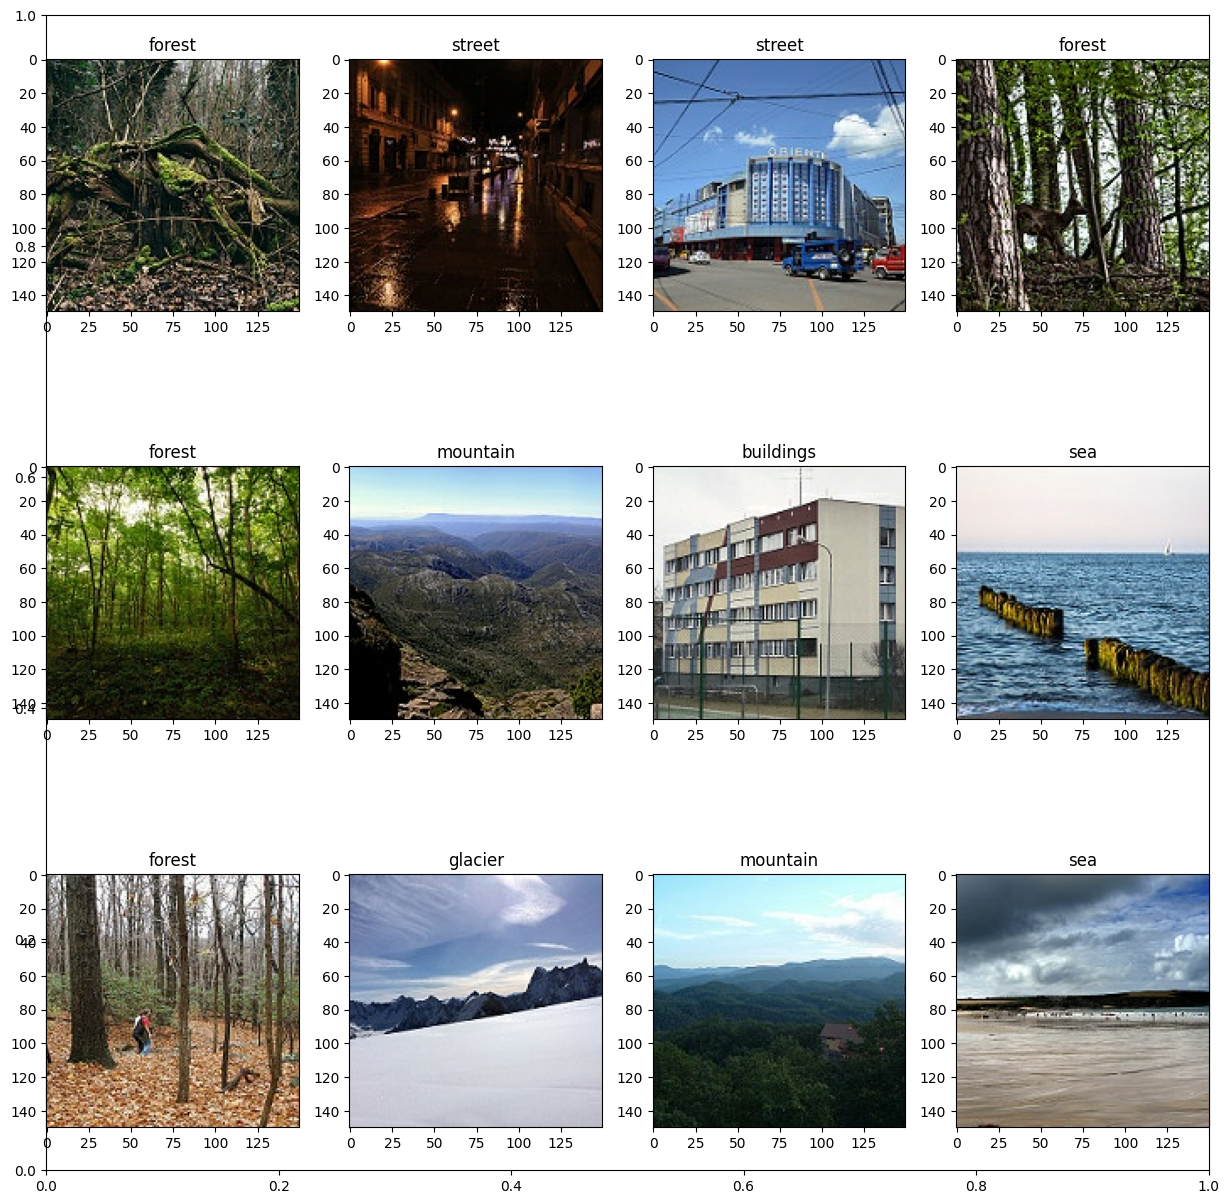

In [14]:
fig,ax=plt.subplots(figsize=(15,15))
for image_batch,labels_batch in train_ds.take(1):
  for i in range(12):
    ax=plt.subplot(3,4,i+1)
    plt.imshow(image_batch[i].numpy().astype("uint8"))
    plt.title(class_names[labels_batch[i]])
    plt.axis

DATA AUGMENTATION

In [15]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.1)
    ])

In [16]:
train_ds=train_ds.map(lambda x,y:(data_augmentation(x,training=True),y))

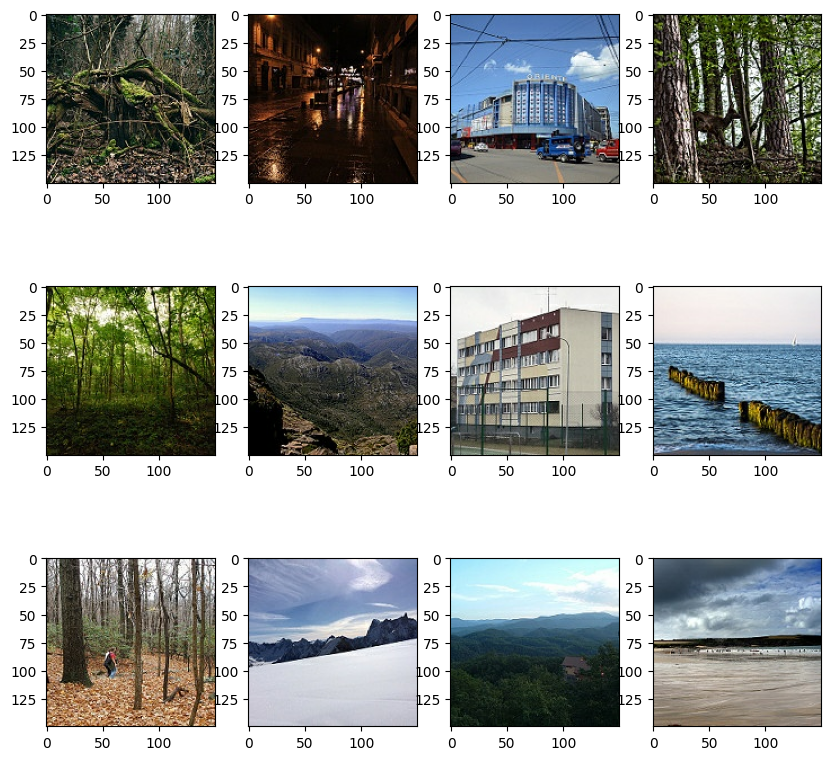

In [17]:
#plotting augumented images

plt.figure(figsize=(10,10))
for image,_ in train_ds.take(1):
  for i in range(12):
    ax=plt.subplot(3,4,i+1)
    plt.imshow(image_batch[i].numpy().astype("uint8"))
    plt.axis

In [18]:
input_shape=(image_size,image_size,3)
n_classes=6


In [19]:
model=models.Sequential([
    layers.Conv2D(32,(3,3),activation='relu',input_shape=input_shape),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3),activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64,activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(n_classes,activation='softmax')
])


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 18496)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,183,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,240,518 (4.73 MB)

 Trainable params: 1,240,518 (4.73 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
model.compile(optimizer="adam",loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),metrics=['accuracy'])


In [22]:
#earlystopping

early_stopping=tf.keras.callbacks.EarlyStopping(monitor='val_loss',patience=5,restore_best_weights=True,min_delta=0.001)

In [23]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_cnn_model.keras",
    monitor="val_loss",
    save_best_only=True
)

In [24]:
history=model.fit(train_ds,epochs=epochs,batch_size=batch_size,verbose=1,validation_data=val_ds,callbacks=[early_stopping,checkpoint])

Epoch 1/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 77s 202ms/step - accuracy: 0.1765 - loss: 3.1330 - val_accuracy: 0.1832 - val_loss: 1.7911
Epoch 2/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 66s 188ms/step - accuracy: 0.1779 - loss: 1.7911 - val_accuracy: 0.1832 - val_loss: 1.7909
Epoch 3/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 63s 179ms/step - accuracy: 0.1779 - loss: 1.7910 - val_accuracy: 0.1832 - val_loss: 1.7908
Epoch 4/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 62s 177ms/step - accuracy: 0.1779 - loss: 1.7910 - val_accuracy: 0.1832 - val_loss: 1.7908
Epoch 5/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 62s 175ms/step - accuracy: 0.1779 - loss: 1.7910 - val_accuracy: 0.1832 - val_loss: 1.7908
Epoch 6/50
351/351 ━━━━━━━━━━━━━━━━━━━━ 62s 177ms/step - accuracy: 0.1779 - loss: 1.7910 - val_accuracy: 0.1832 - val_loss: 1.7908


In [25]:
acc=history.history['accuracy']
val_acc=history.history['val_accuracy']

loss=history.history['loss']
val_loss=history.history['val_loss']

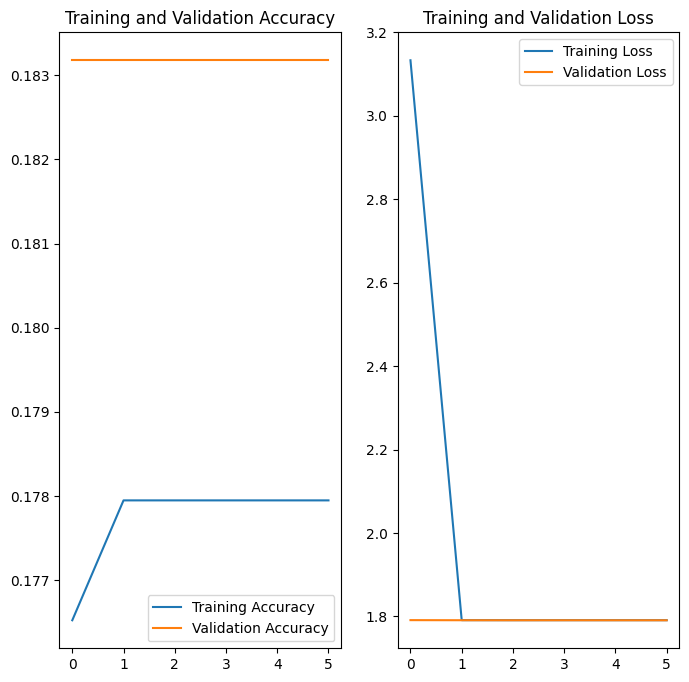

In [26]:
import matplotlib.pyplot as plt

#plotting
plt.figure(figsize=(8,8))
plt.subplot(1,2,1)
plt.plot(range(len(acc)),acc,label='Training Accuracy')
plt.plot(range(len(acc)),val_acc,label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1,2,2)
plt.plot(range(len(loss)),loss,label='Training Loss')
plt.plot(range(len(loss)),val_loss,label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [27]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 28ms/step - accuracy: 0.1750 - loss: 1.7909
Test Loss: 1.790866494178772
Test Accuracy: 0.17499999701976776


In [28]:
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Actual labels:", y_true.shape)
print("Predicted labels:", y_pred.shape)

Actual labels: (3000,)
Predicted labels: (3000,)


In [29]:
from sklearn.metrics import classification_report

class_names = test_ds.class_names

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

   buildings       0.00      0.00      0.00       437
      forest       0.00      0.00      0.00       474
     glacier       0.00      0.00      0.00       553
    mountain       0.17      1.00      0.30       525
         sea       0.00      0.00      0.00       510
      street       0.00      0.00      0.00       501

    accuracy                           0.17      3000
   macro avg       0.03      0.17      0.05      3000
weighted avg       0.03      0.17      0.05      3000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


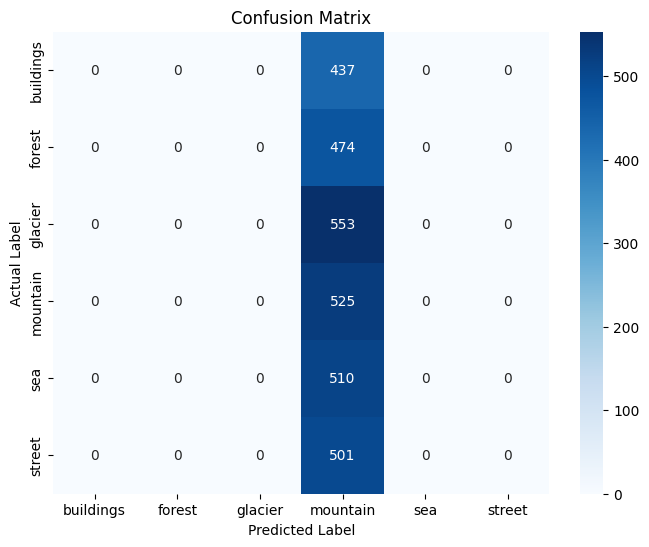

In [30]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")
plt.show()

In [31]:
shuffle=False

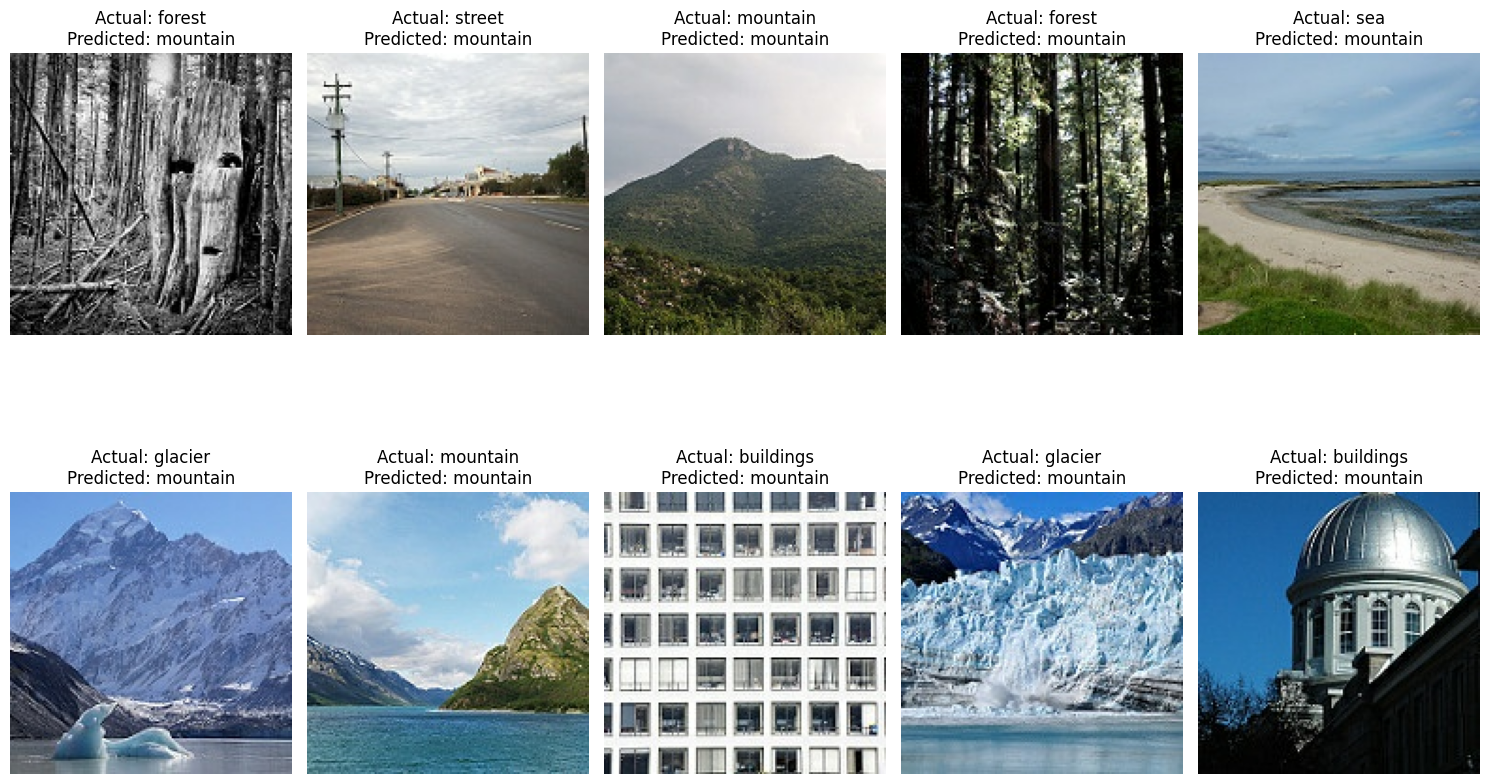

In [32]:
import random
import matplotlib.pyplot as plt

# Collect test images and labels
test_images = []
test_labels = []

for images, labels in test_ds:
    test_images.extend(images.numpy())
    test_labels.extend(labels.numpy())

test_images = np.array(test_images)
test_labels = np.array(test_labels)

# Select 10 random images
random_indices = random.sample(
    range(len(test_images)),
    10
)

plt.figure(figsize=(15, 10))

for i, index in enumerate(random_indices):

    image = test_images[index]
    actual_label = test_labels[index]

    # Predict
    prediction = model.predict(
        np.expand_dims(image, axis=0),
        verbose=0
    )

    predicted_label = np.argmax(prediction)

    plt.subplot(2, 5, i + 1)

    plt.imshow(image.astype("uint8"))

    plt.title(
        f"Actual: {class_names[actual_label]}\n"
        f"Predicted: {class_names[predicted_label]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()